#Baseline Model Data Creation




```
## קוד מקצה לקצה: איסוף 219 מבזקים ועיבוד ה-Baseline

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import os

DATA_DIR = "/content/drive/MyDrive/From_News_to_Action/DataSets/BaseLine"

# מיפוי ידני ומדויק של מספר השורות שיש לדלג עליהן בכל קובץ (על סמך ניסוי הסריקה שלנו)
# המטרה: להגיע ישירות לשורת הנתונים הראשונה
skip_rows_mapping = {
    't01_01': 3, 't01_02': 3, 't01_03': 3, 't01_04': 3, 't01_05': 3,
    't01_06': 3, 't01_07': 3, 't01_08': 3, 't01_09': 3, 't01_10': 3,
    't01_11': 3, 't01_12': 3, 't01_13': 3, 't01_14': 4, 'sep 2026': 5
}

validated_datasets = {}

print("⚙️ מריץ טעינה סופית ומאובטחת לשמירה על כל עמודות המידע...")
print("=" * 60)

for file_prefix, skip_count in skip_rows_mapping.items():
    file = f"{file_prefix}.xlsx"
    full_path = os.path.join(DATA_DIR, file)

    try:
        # טעינה ללא הגדרת כותרת כדי למנוע מחיקת עמודות Unnamed
        df_clean = pd.read_excel(full_path, header=None, skiprows=skip_count)

        # הסרת שורות ועמודות שכולן ריקות לחלוטין (NaN)
        df_clean = df_clean.dropna(how='all').dropna(axis=1, how='all')

        # אינדוקס העמודות בצורה נקייה: עמודה 0 תהיה המשתנה המילולי, ושאר העמודות הן הנתונים
        df_clean.columns = [f"col_{i}" for i in range(df_clean.shape[1])]

        validated_datasets[file_prefix] = df_clean
        print(f"✅ {file} נטען בהצלחה! מימדים סופיים: {df_clean.shape}")

    except Exception as e:
        print(f"❌ כשל בטעינת {file}: {e}")

print(f"\n🎉 המאגרים מוכנים ומלאים בתוך validated_datasets! אפשר להמשיך הלאה.")


⚙️ מריץ טעינה סופית ומאובטחת לשמירה על כל עמודות המידע...
✅ t01_01.xlsx נטען בהצלחה! מימדים סופיים: (35, 12)
✅ t01_02.xlsx נטען בהצלחה! מימדים סופיים: (30, 12)
✅ t01_03.xlsx נטען בהצלחה! מימדים סופיים: (55, 34)
✅ t01_04.xlsx נטען בהצלחה! מימדים סופיים: (41, 15)
✅ t01_05.xlsx נטען בהצלחה! מימדים סופיים: (39, 10)
✅ t01_06.xlsx נטען בהצלחה! מימדים סופיים: (59, 20)
✅ t01_07.xlsx נטען בהצלחה! מימדים סופיים: (64, 20)
✅ t01_08.xlsx נטען בהצלחה! מימדים סופיים: (90, 20)
✅ t01_09.xlsx נטען בהצלחה! מימדים סופיים: (91, 22)
✅ t01_10.xlsx נטען בהצלחה! מימדים סופיים: (91, 20)
✅ t01_11.xlsx נטען בהצלחה! מימדים סופיים: (35, 20)
✅ t01_12.xlsx נטען בהצלחה! מימדים סופיים: (35, 20)
✅ t01_13.xlsx נטען בהצלחה! מימדים סופיים: (172, 16)
✅ t01_14.xlsx נטען בהצלחה! מימדים סופיים: (37, 18)
✅ sep 2026.xlsx נטען בהצלחה! מימדים סופיים: (49, 12)

🎉 המאגרים מוכנים ומלאים בתוך validated_datasets! אפשר להמשיך הלאה.


#Baseline Run

In [ ]:
# ========================================== #
# 0. Setup, Drive Mount and Imports
# ========================================== #
!pip install googlemaps telethon pandas tqdm scipy beautifulsoup4 python-bidi

import os
import asyncio
import json
import requests
import time
import googlemaps
import numpy as np
import pandas as pd
import traceback
from tqdm.notebook import tqdm as tqdm_notebook
from typing import List, Tuple, Optional
from pydantic import BaseModel, Field
from bs4 import BeautifulSoup
from google import genai
from google.genai import types
from google.genai.errors import APIError
from google.colab import userdata, drive
from telethon import TelegramClient
from scipy.spatial.distance import pdist, squareform

print("STATUS: Mounting Google Drive...", flush=True)
drive.mount('/content/drive')

DRIVE_DIR = "/content/drive/MyDrive/News_To_Action_Project/"
os.makedirs(DRIVE_DIR, exist_ok=True)
RAW_CSV_PATH = os.path.join(DRIVE_DIR, "accident_reports_raw.csv")
RESULTS_JSON_PATH = os.path.join(DRIVE_DIR, "accident_reports_baseline_results.json")


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 804.1/804.1 kB 17.8 MB/s  0:00:00
  Created wheel for googlemaps: filename=googlemaps-4.10.0-py3-none-any.whl size=40819 sha256=e126149e5c73e2592e4a1966e9bbe9e02ebf23924411e777b11366405b49c48e
  Stored in directory: /root/.cache/pip/wheels/76/2a/24/5993a7b77c9a37b86f415096436a448c1babdd132066bdcb31
  Created wheel for pyaes: filename=pyaes-1.6.1-py3-none-any.whl size=26422 sha256=4769642016b6abf927b2faaac1e2554481a358d7175a5595548bb7ea2b119aa7
  Stored in directory: /root/.cache/pip/wheels/cf/2b/cc/2cd1fc992150692e118eb782ca44536ebc2b566823353085ba
Successfully built googlemaps pyaes
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [goo

In [ ]:

# ========================================== #
# 1. Schema Definitions and Keys
# ========================================== #
class TrafficAccidentExtract(BaseModel):
    accident_severity: str = Field(description="Accident severity: light, moderate, severe, fatal, or not specified")
    vehicle_types: List[str] = Field(description="List of vehicles involved like bus, motorcycle, car, truck, electric scooter")
    vulnerable_users_and_ages: str = Field(description="Vulnerable road users and ages mentioned")
    human_factor: str = Field(description="Human factor mentioned like distraction, speeding, red light running")
    verbal_location: str = Field(description="The most exact verbal location description for geocoding")

try:
    GEMINI_KEY = userdata.get('News_to_Action')
    MAPS_KEY = userdata.get('Google_Map')
    TELEGRAM_API_ID = int(userdata.get('TELEGRAM_API_ID'))
    TELEGRAM_API_HASH = userdata.get('TELEGRAM_API_HASH')
    print("STATUS: Keys loaded successfully from Secrets!", flush=True)
except Exception as e:
    print(f"ERROR: Error loading keys: {e}", flush=True)

KEYWORDS = ["תאונ", "דרכים", "התנגש", "רכב", "אופנוע", "הולך רגל", "נפגע", "פצוע", "מחלף", "צומת"]


STATUS: Keys loaded successfully from Secrets!


In [ ]:
from datetime import datetime
from typing import List, Dict

async def scrape_telegram_channel(client: TelegramClient, target_channel: str, limit_to_collect: int = 50) -> List[Dict]:
    print(f"INFO: [Telegram] Scraping channel: {target_channel}...", flush=True)
    accident_records = []
    try:
        async for message in client.iter_messages(target_channel, limit=1000):
            if len(accident_records) >= limit_to_collect:
                break
            if message.text:
                text = message.text.strip()
                if any(keyword in text for keyword in KEYWORDS):
                    # שליפת התאריך והשעה המדויקים של הודעת הטלגרם
                    pub_date = message.date.replace(tzinfo=None).isoformat() if message.date else datetime.now().isoformat()
                    accident_records.append({
                        'source': target_channel,
                        'raw_text': text,
                        'published_date': pub_date
                    })
    except Exception as e:
        print(f"ERROR: Error scraping telegram channel {target_channel}: {e}", flush=True)
    print(f"INFO: [Telegram] Collected {len(accident_records)} posts from {target_channel}", flush=True)
    return accident_records

def scrape_web_source(url: str, source_name: str, limit_to_collect: int = 50) -> List[Dict]:
    print(f"INFO: [Web] Scraping site {source_name} ({url})...", flush=True)
    accident_records = []
    headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36"}
    try:
        response = requests.get(url, headers=headers, timeout=15)
        if response.status_code == 200:
            soup = BeautifulSoup(response.content, 'html.parser')
            potential_elements = soup.find_all(['h1', 'h2', 'h3', 'p', 'span', 'a'])
            seen_texts = set()
            for element in potential_elements:
                if len(accident_records) >= limit_to_collect:
                    break
                text = element.get_text().strip()
                if len(text) > 20 and text not in seen_texts:
                    if any(keyword in text for keyword in KEYWORDS):
                        seen_texts.add(text)
                        # חיפוש תגית זמן סמוכה באלמנט האב, או ברירת מחדל לזמן האיסוף
                        parent_time = element.find_parent().find('time') if element.find_parent() else None
                        pub_date = parent_time.get('datetime') if (parent_time and parent_time.get('datetime')) else datetime.now().isoformat()
                        accident_records.append({
                            'source': source_name,
                            'raw_text': text,
                            'published_date': pub_date
                        })
        else:
            print(f"WARNING: Site {source_name} returned status code: {response.status_code}", flush=True)
    except Exception as e:
        print(f"ERROR: Error scraping site {source_name}: {e}", flush=True)
    print(f"INFO: [Web] Collected {len(accident_records)} articles from {source_name}", flush=True)
    return accident_records

async def build_multi_source_eval_set(csv_path: str):
    all_collected_data = []
    client = TelegramClient('session_multi_source', TELEGRAM_API_ID, TELEGRAM_API_HASH)
    await client.start()

    telegram_sources = {'mdaisrael': 50, 'uh1221': 50, 'hamalnews': 50, 'fireisrael7777': 50}
    for channel, limit in telegram_sources.items():
        records = await scrape_telegram_channel(client, channel, limit)
        all_collected_data.extend(records)
    await client.disconnect()

    web_sources = {
        'ynet': 'https://ynet.co.il',
        'maariv': 'https://maariv.co.il',
        'israelhayom': 'https://israelhayom.co.il',
        'emess': 'https://emess.co.il'
    }
    for source_name, url in web_sources.items():
        records = await asyncio.to_thread(scrape_web_source, url, source_name, limit_to_collect=50)
        all_collected_data.extend(records)
        await asyncio.sleep(1)

    df = pd.DataFrame(all_collected_data)
    df.to_csv(csv_path, index=False, encoding='utf-8-sig')
    print(f"INFO: Data collection finished! Total {len(df)} rows with dates saved to: {csv_path}", flush=True)


In [ ]:
import asyncio
import pandas as pd
import requests
from bs4 import BeautifulSoup
from datetime import datetime
from typing import List, Dict
from telethon import TelegramClient

async def scrape_telegram_channel(client: TelegramClient, target_channel: str, limit_to_collect: int = 150) -> List[Dict]:
    print(f"📡 [Telegram] סורק את הערוץ: {target_channel}...", flush=True)
    accident_records = []
    try:
        async for message in client.iter_messages(target_channel, limit=2500):
            if len(accident_records) >= limit_to_collect:
                break
            if message.text:
                text = message.text.strip()
                if any(keyword in text for keyword in KEYWORDS):
                    pub_date = message.date.replace(tzinfo=None).isoformat() if message.date else datetime.now().isoformat()
                    accident_records.append({
                        'source': target_channel,
                        'raw_text': text,
                        'published_date': pub_date
                    })
        print(f"   ✅ נאספו {len(accident_records)} דיווחים עם תאריך מ-{target_channel}", flush=True)
    except Exception as e:
        print(f"   ❌ שגיאה בסריקת ערוץ {target_channel}: {e}", flush=True)
    return accident_records

def scrape_web_source(url: str, source_name: str, limit_to_collect: int = 50) -> List[Dict]:
    print(f"🌐 [Web] סורק את האתר: {source_name}...", flush=True)
    accident_records = []
    headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36"}
    try:
        response = requests.get(url, headers=headers, timeout=15)
        if response.status_code == 200:
            soup = BeautifulSoup(response.content, 'html.parser')
            seen_texts = set()
            for element in soup.find_all(['h1', 'h2', 'h3', 'p', 'span', 'a']):
                if len(accident_records) >= limit_to_collect:
                    break
                text = element.get_text().strip()
                if len(text) > 20 and text not in seen_texts and any(keyword in text for keyword in KEYWORDS):
                    seen_texts.add(text)
                    parent_time = element.find_parent().find('time') if element.find_parent() else None
                    pub_date = parent_time.get('datetime') if (parent_time and parent_time.get('datetime')) else datetime.now().isoformat()
                    accident_records.append({
                        'source': source_name,
                        'raw_text': text,
                        'published_date': pub_date
                    })
            print(f"   ✅ נאספו {len(accident_records)} כתבות עם תאריך מ-{source_name}", flush=True)
        else:
            print(f"   ⚠️ האתר {source_name} החזיר קוד שגיאה: {response.status_code}", flush=True)
    except Exception as e:
        print(f"   ❌ שגיאה בסריקת האתר {source_name}: {e}", flush=True)
    return accident_records

async def build_multi_source_eval_set(csv_path: str):
    all_collected_data = []
    try:
        print("🚀 מתחיל תהליך איסוף נתונים ותאריכים...", flush=True)
        client = TelegramClient('session_multi_source', TELEGRAM_API_ID, TELEGRAM_API_HASH)
        await client.start()

        telegram_sources = {'mdaisrael': 150, 'uh1221': 150, 'hamalnews': 150, 'fireisrael7777': 150}
        for channel, limit in telegram_sources.items():
            records = await scrape_telegram_channel(client, channel, limit)
            all_collected_data.extend(records)
        await client.disconnect()

        web_sources = {
            'ynet': 'https://ynet.co.il',
            'maariv': 'https://maariv.co.il',
            'israelhayom': 'https://israelhayom.co.il',
            'emess': 'https://emess.co.il'
        }
        for source_name, url in web_sources.items():
            records = await asyncio.to_thread(scrape_web_source, url, source_name, limit_to_collect=50)
            all_collected_data.extend(records)
            await asyncio.sleep(1)

        if all_collected_data:
            df = pd.DataFrame(all_collected_data)
            df.to_csv(csv_path, index=False, encoding='utf-8-sig')
            print(f"\n🎉 הצלחה! נשמרו {len(df)} רשומות עם תאריכים בקובץ: {csv_path}", flush=True)
        else:
            print("\n⚠️ האיסוף הסתיים אך לא נמצאו רשומות תואמות (בדקי שמשתנה KEYWORDS מוגדר).", flush=True)

    except Exception as e:
        print(f"\n❌ כשל כללי בהרצת האיסוף: {e}", flush=True)

# הפעלה מיידית של האיסוף!
await build_multi_source_eval_set("temp_dates.csv")


🚀 מתחיל תהליך איסוף נתונים ותאריכים...
Please enter your phone (or bot token): +972544758173
Please enter the code you received: 49450
Signed in successfully as Ravit BarLev; remember to not break the ToS or you will risk an account ban!
📡 [Telegram] סורק את הערוץ: mdaisrael...
   ✅ נאספו 150 דיווחים עם תאריך מ-mdaisrael
📡 [Telegram] סורק את הערוץ: uh1221...
   ✅ נאספו 150 דיווחים עם תאריך מ-uh1221
📡 [Telegram] סורק את הערוץ: hamalnews...
   ✅ נאספו 150 דיווחים עם תאריך מ-hamalnews
📡 [Telegram] סורק את הערוץ: fireisrael7777...
   ✅ נאספו 150 דיווחים עם תאריך מ-fireisrael7777
🌐 [Web] סורק את האתר: ynet...
   ✅ נאספו 3 כתבות עם תאריך מ-ynet
🌐 [Web] סורק את האתר: maariv...
   ✅ נאספו 2 כתבות עם תאריך מ-maariv
🌐 [Web] סורק את האתר: israelhayom...
   ⚠️ האתר israelhayom החזיר קוד שגיאה: 403
🌐 [Web] סורק את האתר: emess...
   ✅ נאספו 8 כתבות עם תאריך מ-emess

🎉 הצלחה! נשמרו 613 רשומות עם תאריכים בקובץ: temp_dates.csv


In [ ]:

# ========================================== #
# 2. Scrapers Functions
# ========================================== #
async def scrape_telegram_channel(client: TelegramClient, target_channel: str, limit_to_collect: int = 50) -> List[str]:
    print(f"INFO: [Telegram] Scraping channel: {target_channel}...", flush=True)
    accident_texts = []
    try:
        async for message in client.iter_messages(target_channel, limit=1000):
            if len(accident_texts) >= limit_to_collect:
                break
            if message.text:
                text = message.text.strip()
                if any(keyword in text for keyword in KEYWORDS):
                    accident_texts.append(text)
    except Exception as e:
        print(f"ERROR: Error scraping telegram channel {target_channel}: {e}", flush=True)
    print(f"INFO: [Telegram] Collected {len(accident_texts)} posts from {target_channel}", flush=True)
    return accident_texts

def scrape_web_source(url: str, source_name: str, limit_to_collect: int = 50) -> List[str]:
    print(f"INFO: [Web] Scraping site {source_name} ({url})...", flush=True)
    accident_texts = []
    headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36"}
    try:
        response = requests.get(url, headers=headers, timeout=15)
        if response.status_code == 200:
            soup = BeautifulSoup(response.content, 'html.parser')
            potential_elements = soup.find_all(['h1', 'h2', 'h3', 'p', 'span', 'a'])
            seen_texts = set()
            for element in potential_elements:
                if len(accident_texts) >= limit_to_collect:
                    break
                text = element.get_text().strip()
                if len(text) > 20 and text not in seen_texts:
                    if any(keyword in text for keyword in KEYWORDS):
                        seen_texts.add(text)
                        accident_texts.append(text)
        else:
            print(f"WARNING: Site {source_name} returned status code: {response.status_code}", flush=True)
    except Exception as e:
        print(f"ERROR: Error scraping site {source_name}: {e}", flush=True)
    print(f"INFO: [Web] Collected {len(accident_texts)} articles from {source_name}", flush=True)
    return accident_texts

async def build_multi_source_eval_set(csv_path: str):
    all_collected_data = []
    client = TelegramClient('session_multi_source', TELEGRAM_API_ID, TELEGRAM_API_HASH)
    await client.start()

    telegram_sources = {'mdaisrael': 50, 'uh1221': 50, 'hamalnews': 50, 'fireisrael7777': 50}
    for channel, limit in telegram_sources.items():
        reports = await scrape_telegram_channel(client, channel, limit)
        for r in reports:
            all_collected_data.append({'source': channel, 'raw_text': r})
    await client.disconnect()

    web_sources = {
        'ynet': 'https://ynet.co.il',
        'maariv': 'https://maariv.co.il',
        'israelhayom': 'https://israelhayom.co.il',
        'emess': 'https://emess.co.il'
    }
    for source_name, url in web_sources.items():
        reports = await asyncio.to_thread(scrape_web_source, url, source_name, limit_to_collect=50)
        for r in reports:
            all_collected_data.append({'source': source_name, 'raw_text': r})
        await asyncio.sleep(1)

    df = pd.DataFrame(all_collected_data)
    df.to_csv(csv_path, index=False, encoding='utf-8-sig')
    print(f"INFO: Data collection finished! Total {len(df)} rows saved to: {csv_path}", flush=True)


In [ ]:
# ========================================== #
# 3. Processing and Core Logics (FAST PAID TIER)
# ========================================== #
def geocode_with_google(verbal_location: str, gmaps_client: googlemaps.Client) -> Tuple[Optional[float], Optional[float]]:
    if not verbal_location or verbal_location.strip() == "" or "not specified" in verbal_location:
        return None, None
    try:
        geocode_result = gmaps_client.geocode(f"{verbal_location}, Israel")
        if geocode_result:
            location = geocode_result[0]['geometry']['location']
            return float(location['lat']), float(location['lng'])
    except Exception:
        pass
    return None, None

def safe_generate_content(client: genai.Client, model_name: str, contents: str, config=None) -> str:
    # מנגנון קצר ומהיר מאחר שהחשבון שלכן מאובטח ובתשלום
    max_retries = 3
    retry_delay = 2.0
    for attempt in range(max_retries):
        try:
            response = client.models.generate_content(model=model_name, contents=contents, config=config)
            return response.text
        except APIError as e:
            err_msg = str(e).lower()
            if any(x in err_msg for x in ["quota", "429", "limit", "demand", "resource_exhausted"]):
                print(f"\n⏳ [Paid Tier Warning] Waiting {retry_delay}s...", flush=True)
                time.sleep(retry_delay)
                retry_delay *= 2.0
                continue
            raise e
    raise RuntimeError("API failure.")

def run_baseline_pipeline_with_google(raw_text: str, gemini_client: genai.Client, gmaps_client: googlemaps.Client) -> dict:
    prompt = f"Analyze this traffic report and extract fields into the requested structure:\n{raw_text}"
    config = types.GenerateContentConfig(
        response_mime_type="application/json",
        response_schema=TrafficAccidentExtract,
        temperature=0.0
    )
    # שימוש רשמי ומהיר ב-gemini-3.8-flash ללא מגבלות
    raw_response = safe_generate_content(gemini_client, 'gemini-3.8-flash', prompt, config)
    result_json = json.loads(raw_response)
    lat, lon = geocode_with_google(result_json['verbal_location'], gmaps_client)
    result_json['latitude'] = lat
    result_json['longitude'] = lon
    return result_json

def calculate_spatial_hotspots(processed_list: List[dict]) -> List[dict]:
    print("INFO: [Step 3: Calculating Spatial Hotspots]", flush=True)
    coords = [[r['latitude'], r['longitude']] for r in processed_list if r.get('latitude') is not None and r.get('longitude') is not None]

    if len(coords) <= 1:
        print("WARNING: Not enough valid coordinates to calculate hotspots.", flush=True)
        for idx in range(len(processed_list)):
            processed_list[idx]['nearby_accidents_count'] = 0
            processed_list[idx]['is_hotspot'] = False
        return processed_list

    print(f"INFO: Found {len(coords)} valid coordinates for analysis.", flush=True)
    coords_np = np.array(coords)
    dist_matrix = squareform(pdist(coords_np)) * 111.0
    radius_km = 1.5
    hotspot_counts = np.sum(dist_matrix <= radius_km, axis=1) - 1

    valid_coord_idx = 0
    for r in processed_list:
        if r.get('latitude') is not None and r.get('longitude') is not None:
            r['nearby_accidents_count'] = int(hotspot_counts[valid_coord_idx])
            r['is_hotspot'] = bool(hotspot_counts[valid_coord_idx] >= 3)
            valid_coord_idx += 1
        else:
            r['nearby_accidents_count'] = 0
            r['is_hotspot'] = False

    num_hotspots_found = sum(1 for r in processed_list if r.get('is_hotspot') is True)
    print(f"INFO: Analysis done. Found {num_hotspots_found} hotspot reports.", flush=True)
    return processed_list

async def main_pipeline() -> List[dict]:
    if not os.path.exists(RAW_CSV_PATH):
        print("INFO: Raw data not found. Starting multi-source collection...", flush=True)
        await build_multi_source_eval_set(RAW_CSV_PATH)

    df_raw = pd.read_csv(RAW_CSV_PATH)
    total_rows = len(df_raw)
    print(f"INFO: Loaded {total_rows} raw reports for model processing.", flush=True)

    gemini_client = genai.Client(api_key=GEMINI_KEY)
    gmaps_client = googlemaps.Client(key=MAPS_KEY)
    global_processed_results = []

    print("INFO: [Starting Model Processing Loop]")
    for index, row in df_raw.iterrows():
        current_idx = index + 1
        src = row['source']
        txt = row['raw_text']
        print(f"INFO: [{current_idx}/{total_rows}] Processing row from '{src}'...", end="", flush=True)
        try:
            start_time = time.time()
            res_dict = run_baseline_pipeline_with_google(txt, gemini_client, gmaps_client)
            res_dict['source'] = src
            res_dict['raw_text'] = txt
            global_processed_results.append(res_dict)
            elapsed = time.time() - start_time
            print(f" -> SUCCESS! ({elapsed:.1f}s)", flush=True)

            # ביטול השהיית 12 השניות! השארנו 0.2 שניות סמליות רק כדי לא להעמיס על זיכרון הלוקאל של ה-Notebook
            time.sleep(0.2)
        except Exception as row_err:
            print(" -> FAILED!", flush=True)
            print(f"ERROR: Error details for row {current_idx}: {row_err}", flush=True)
            continue
    return global_processed_results

if __name__ == "__main__":
    print("STATUS: Starting main pipeline...", flush=True)
    results_from_api = await main_pipeline()
    final_json_data = calculate_spatial_hotspots(results_from_api)

    print(f"STATUS: Saving {len(final_json_data)} processed results to Drive...", flush=True)
    with open(RESULTS_JSON_PATH, 'w', encoding='utf-8') as f:
        json.dump(final_json_data, f, ensure_ascii=False, indent=4)
    print(f"STATUS: Process finished successfully! Output file ready at:\n📁 {RESULTS_JSON_PATH}", flush=True)


STATUS: Starting main pipeline...
INFO: Loaded 219 raw reports for model processing.
INFO: [Starting Model Processing Loop]
INFO: [1/219] Processing row from 'mdaisrael'... -> SUCCESS! (3.8s)
INFO: [2/219] Processing row from 'mdaisrael'... -> SUCCESS! (5.0s)
INFO: [3/219] Processing row from 'mdaisrael'... -> SUCCESS! (3.8s)
INFO: [4/219] Processing row from 'mdaisrael'... -> SUCCESS! (6.5s)
INFO: [5/219] Processing row from 'mdaisrael'... -> SUCCESS! (8.0s)
INFO: [6/219] Processing row from 'mdaisrael'... -> SUCCESS! (2.9s)
INFO: [7/219] Processing row from 'mdaisrael'... -> SUCCESS! (3.8s)
INFO: [8/219] Processing row from 'mdaisrael'... -> SUCCESS! (6.4s)
INFO: [9/219] Processing row from 'mdaisrael'... -> SUCCESS! (6.1s)
INFO: [10/219] Processing row from 'mdaisrael'... -> SUCCESS! (6.6s)
INFO: [11/219] Processing row from 'mdaisrael'... -> SUCCESS! (4.3s)
INFO: [12/219] Processing row from 'mdaisrael'... -> SUCCESS! (7.4s)
INFO: [13/219] Processing row from 'mdaisrael'... -> SUCC

##יצירת הגרפים והניתוח הסטטיסטי מתוך ה-Eval-Set

📂 [Drive] הנתונים נטענו בהצלחה! נמצאו 219 תאונות מעובדות.


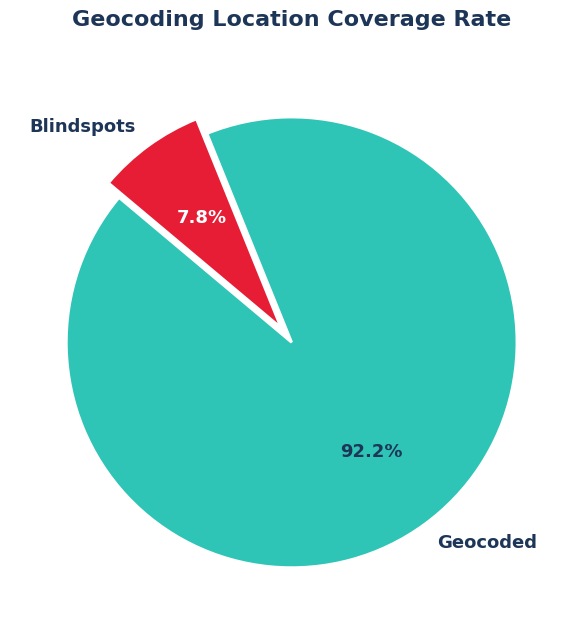

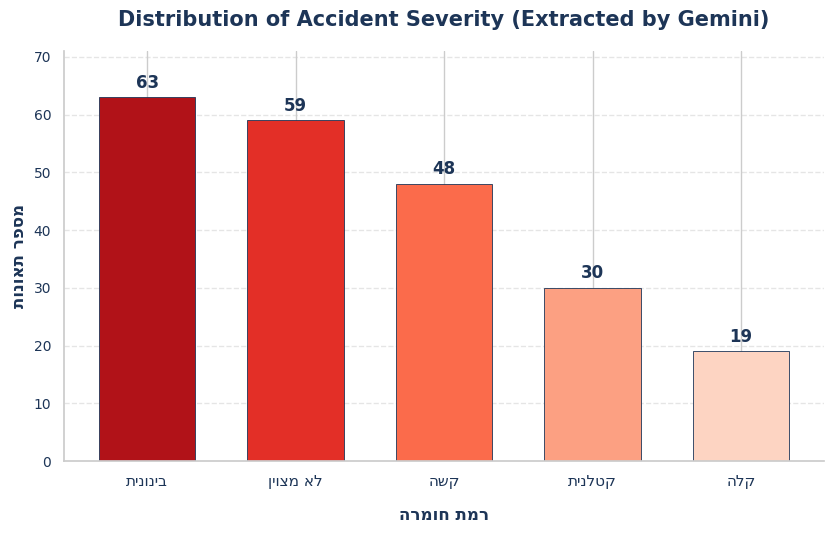

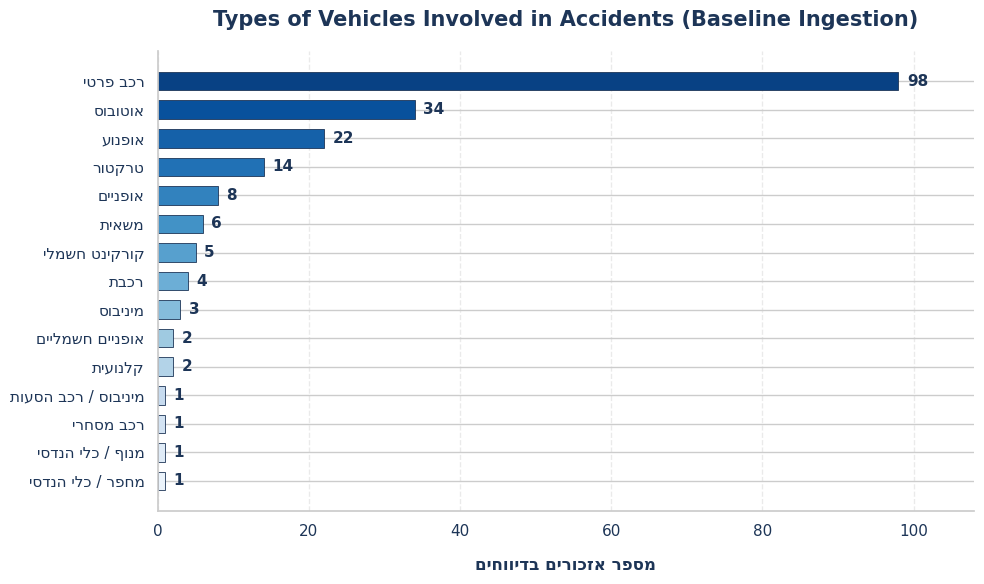

<Figure size 950x550 with 0 Axes>

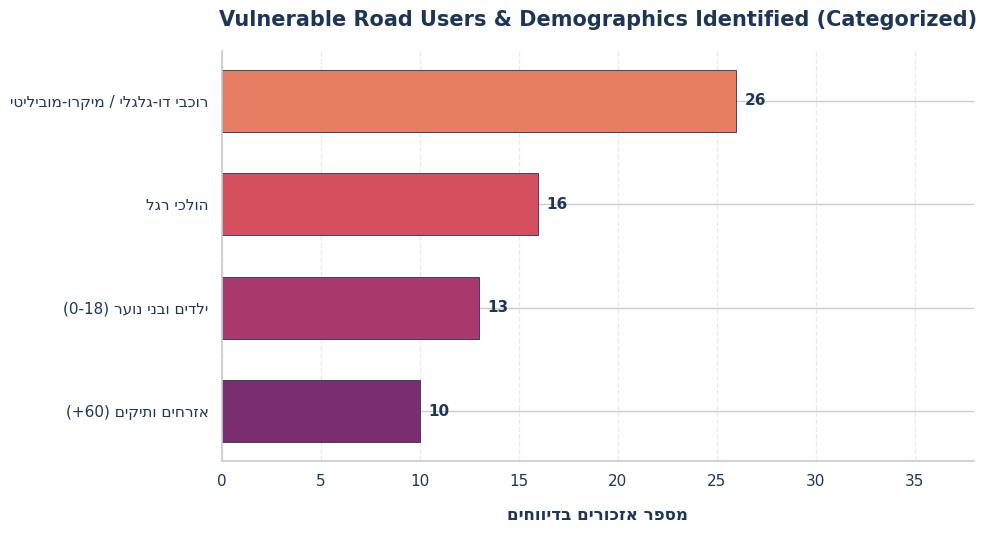

In [ ]:
# ==========================================
# 0. התקנת ספריית התמיכה בכתב דו-כיווני (BiDi) למניעת כתב ראי
# ==========================================
!pip install -q python-bidi

import os
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from bidi.algorithm import get_display

# 1. הגדרת נתיבי קובץ התוצאות הרשמי בפורמט JSON כפי שנוצר בדרייב
DRIVE_PATH = "/content/drive/MyDrive/News_To_Action_Project/accident_reports_baseline_results.json"
LOCAL_PATH = "accident_reports_baseline_results.json"

df = None

# בדיקה וטעינה אוטומטית של קובץ ה-JSON
if os.path.exists(DRIVE_PATH):
    try:
        with open(DRIVE_PATH, 'r', encoding='utf-8') as f:
            df = pd.DataFrame(json.load(f))
        print(f"📂 [Drive] הנתונים נטענו בהצלחה! נמצאו {len(df)} תאונות מעובדות.")
    except Exception as e:
        print(f"⚠️ שגיאה בקריאת קובץ ה-JSON מהדרייב: {e}")

elif os.path.exists(LOCAL_PATH):
    try:
        with open(LOCAL_PATH, 'r', encoding='utf-8') as f:
            df = pd.DataFrame(json.load(f))
        print(f"📂 [Local] הנתונים נטענו בהצלחה מהתיקייה המקומית!")
    except Exception as e:
        print(f"⚠️ שגיאה בקריאת הקובץ המקומי: {e}")

# ==========================================
# 🛠️ בדיקת הגנה: עצירה נקייה במידה והעיבוד של ה-LLM טרם הסתיים
# ==========================================
if df is None or df.empty:
    print("\n❌ עצירה: קובץ התוצאות המעובד ('accident_reports_baseline_results.json') עדיין לא נוצר.")
    print("👉 פתרון: ודאו שהרצתן את תא העיבוד הראשי והמתנה מלאה עד לסיום העיבוד מול Gemini.")
else:
    # פונקציית עזר למניעת היפוך פונטים ועבודה תקינה עם עברית בגרפים
    def fix_hebrew(text):
        if isinstance(text, str):
            return get_display(text)
        return text

    # הגדרת סגנון ויזואלי מובנה ואחיד
    sns.set_theme(style="whitegrid")
    plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
    plt.rcParams['font.family'] = 'sans-serif'

    total_rows = len(df)
    geocoded_success = df['latitude'].notna().sum()
    geocoded_failed = total_rows - geocoded_success
    success_rate = (geocoded_success / total_rows) * 100 if total_rows > 0 else 0

    # ==========================================
    # 📊 גרף 1 המשופר: קצב כיסוי מיקום (Geocoding Coverage)
    # ==========================================
    plt.figure(figsize=(6.5, 6.5))
    colors = ['#2ec4b6', '#e71d36']
    labels_fixed = ['Geocoded', 'Blindspots']
    sizes = [geocoded_success, geocoded_failed]
    explode = (0, 0.08)

    wedges, texts, autotexts = plt.pie(
        sizes,
        explode=explode,
        labels=labels_fixed,
        autopct='%1.1f%%',
        startangle=140,
        colors=colors,
        textprops={'fontsize': 13, 'weight': 'bold', 'color': '#1d3557'},
        wedgeprops={'edgecolor': 'white', 'linewidth': 2}
    )

    if len(autotexts) > 1:
        autotexts[1].set_color('white')

    plt.title("Geocoding Location Coverage Rate", fontsize=16, weight='bold', pad=25, color='#1d3557')
    plt.tight_layout()
    plt.savefig('geocoding_coverage.png', dpi=300)
    plt.show()

    # ==========================================
    # 📊 גרף 2 המשופר: התפלגות התאונות לפי חומרה (מתורגם ונקי)
    # ==========================================
    severity_counts = df['accident_severity'].value_counts()

    if not severity_counts.empty:
        translation_map = {
            'moderate': 'בינונית',
            'not specified': 'לא מצוין',
            'severe': 'קשה',
            'fatal': 'קטלנית',
            'light': 'קלה'
        }

        translated_labels = [fix_hebrew(translation_map.get(str(x).lower(), str(x))) for x in severity_counts.index]

        fig, ax = plt.subplots(figsize=(8.5, 5.5))
        bars = ax.bar(translated_labels, severity_counts.values, color=sns.color_palette("Reds_r", len(severity_counts)),
                      edgecolor='#1d3557', linewidth=0.6, width=0.65)

        ax.set_title("Distribution of Accident Severity (Extracted by Gemini)", fontsize=15, weight='bold', pad=18, color='#1d3557')
        ax.set_xlabel(fix_hebrew("רמת חומרה"), fontsize=12, labelpad=12, color='#1d3557', weight='bold')
        ax.set_ylabel(fix_hebrew("מספר תאונות"), fontsize=12, color='#1d3557', weight='bold')
        ax.set_ylim(0, max(severity_counts.values) + 8)

        ax.tick_params(axis='x', labelsize=11, labelcolor='#1d3557')
        ax.tick_params(axis='y', labelsize=10, labelcolor='#1d3557')

        for bar in bars:
            height = bar.get_height()
            ax.annotate(f'{height}',
                        xy=(bar.get_x() + bar.get_width() / 2, height),
                        xytext=(0, 4),
                        textcoords="offset points",
                        ha='center', va='bottom', fontsize=12, weight='bold', color='#1d3557')

        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_color('#cccccc')
        ax.spines['bottom'].set_color('#cccccc')
        ax.grid(axis='y', linestyle='--', alpha=0.5)

        plt.tight_layout()
        plt.savefig('accident_severity.png', dpi=300)
        plt.show()

    # ==========================================
    # 📊 גרף 3 המשופר: סוגי כלי רכב המעורבים בתאונות (מאוחד, מתורגם ונקי)
    # ==========================================
    if 'vehicle_types' in df.columns:
        df_vehicles = df.explode('vehicle_types')
        df_vehicles['vehicle_types'] = df_vehicles['vehicle_types'].astype(str).str.strip().str.lower()

        vehicle_translation_map = {
            'car': 'רכב פרטי',
            'bus': 'אוטובוס',
            'motorcycle': 'אופנוע',
            'tractor': 'טרקטור',
            'bicycle': 'אופניים',
            'truck': 'משאית',
            'electric scooter': 'קורקינט חשמלי',
            'scooter': 'קורקינט חשמלי',
            'minibus': 'מיניבוס',
            'train': 'רכבת',
            'רכבת': 'רכבת',
            'electric bicycle': 'אופניים חשמליים',
            'mobility scooter': 'קלנועית',
            'רכב הסעות': 'מיניבוס / רכב הסעות',
            'commercial vehicle': 'רכב מסחרי',
            'excavator': 'מחפר / כלי הנדסי',
            'מנוף': 'מנוף / כלי הנדסי'
        }

        df_vehicles['vehicle_mapped'] = df_vehicles['vehicle_types'].map(vehicle_translation_map)
        vehicle_counts = df_vehicles['vehicle_mapped'].value_counts()

        exclude_list = ["אין", "לא מצוין", "", "ספינת תענוגות", "אוניית משא", "nan"]
        vehicle_counts = vehicle_counts[~vehicle_counts.index.isin(exclude_list)]

        if not vehicle_counts.empty:
            fig, ax = plt.subplots(figsize=(10, 6))
            fixed_vehicle_index = [fix_hebrew(x) for x in vehicle_counts.index]

            bars_v = ax.barh(fixed_vehicle_index, vehicle_counts.values,
                             color=sns.color_palette("Blues_r", len(vehicle_counts)),
                             edgecolor='#1d3557', linewidth=0.6, height=0.65)

            ax.invert_yaxis()

            ax.set_title("Types of Vehicles Involved in Accidents (Baseline Ingestion)", fontsize=15, weight='bold', pad=18, color='#1d3557')
            ax.set_xlabel(fix_hebrew("מספר אזכורים בדיווחים"), fontsize=12, labelpad=12, color='#1d3557', weight='bold')
            ax.set_xlim(0, max(vehicle_counts.values) + 10)

            ax.tick_params(axis='x', labelsize=11, labelcolor='#1d3557')
            ax.tick_params(axis='y', labelsize=11, labelcolor='#1d3557')

            for bar in bars_v:
                width = bar.get_width()
                ax.annotate(f'{width}',
                            xy=(width, bar.get_y() + bar.get_height() / 2),
                            xytext=(6, 0),
                            textcoords="offset points",
                            ha='left', va='center', fontsize=11, fontweight='bold', color='#1d3557')

            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.spines['left'].set_color('#cccccc')
            ax.spines['bottom'].set_color('#cccccc')
            ax.grid(axis='x', linestyle='--', alpha=0.4)

            plt.tight_layout()
            plt.savefig('vehicle_types_involved.png', dpi=300)
            plt.show()

        # ==========================================
    # 📊 גרף 4 הסופי והחסין: משתמשי דרך פגיעים וגילאים (סדר לוגי מתוקן)
    # ==========================================
    if 'vulnerable_users_and_ages' in df.columns:
        plt.figure(figsize=(9.5, 5.5))

        # יצירת עותק נקי וסינון ערכים ריקים אמיתיים
        vulnerable_df = df[df['vulnerable_users_and_ages'].notna()].copy()

        # פונקציית איחוד חסינה - קודם כל מחפשת התאמות חיוביות!
        def categorize_vulnerable_final(val):
            # טיפול במקרה שהערך הגיע כרשימה (List) מה-JSON
            if isinstance(val, list):
                text = " ".join([str(x) for x in val]).lower().strip()
            else:
                text = str(val).lower().strip()

            # --- שלב 1: חיפוש קטגוריות סיכון ספציפיות (העשירות ביותר אצלכן) ---

            # קבוצת גיל - אזרחים ותיקים וקשישים
            if any(x in text for x in ["60", "70", "80", "elderly", "קשיש", "מבוגר", "senior", "aged around 60"]):
                return "אזרחים ותיקים (60+)"

            # קבוצת גיל - ילדים ובני נוער
            if any(x in text for x in ["child", "ילד", "boy", "girl", "schoolgirl", "10", "14", "teen", "נער", "young"]):
                return "ילדים ובני נוער (0-18)"

            # רוכבי דו-גלגלי פגיעים (אופנועים, קורקינטים, אופניים)
            if any(x in text for x in ["motorcycle", "scooter", "bicycle", "rider", "רוכב", "bike"]):
                return "רוכבי דו-גלגלי / מיקרו-מוביליטי"

            # הולכי רגל כלליים
            if any(x in text for x in ["pedestrian", "הולך רגל", "הולכת רגל", "woman", "female", "man", "male", "worker", "פועל"]):
                return "הולכי רגל"

            # --- שלב 2: סינון רעשים ומילים ריקות רק אם לא נמצאה התאמה למעלה ---
            if any(x in text for x in ["אין", "לא מצוין", "none", "not specified", "nan", "", "unknown"]):
                return None

            return "משתמשי דרך פגיעים אחרים"

        # החלת פונקציית האיחוד המעודכנת
        vulnerable_df['vulnerable_clean'] = vulnerable_df['vulnerable_users_and_ages'].apply(categorize_vulnerable_final)

        # ספירת המופעים וניקוי ה-None
        vulnerable_counts = vulnerable_df['vulnerable_clean'].dropna().value_counts()

        if not vulnerable_counts.empty:
            fig, ax = plt.subplots(figsize=(10, 5.5))
            fixed_vulnerable_index = [fix_hebrew(x) for x in vulnerable_counts.index]

            # רינדור הברים בצורה מסודרת ונקייה
            bars_vul = ax.barh(fixed_vulnerable_index, vulnerable_counts.values,
                               color=sns.color_palette("flare", len(vulnerable_counts)),
                               edgecolor='#1d3557', linewidth=0.6, height=0.6)

            # היפוך ציר Y שהערך הגבוה ביותר יהיה למעלה
            ax.invert_yaxis()

            # עיצוב כותרות וצירים
            ax.set_title("Vulnerable Road Users & Demographics Identified (Categorized)", fontsize=15, weight='bold', pad=18, color='#1d3557')
            ax.set_xlabel(fix_hebrew("מספר אזכורים בדיווחים"), fontsize=12, labelpad=12, color='#1d3557', weight='bold')
            ax.set_xlim(0, max(vulnerable_counts.values) + 12) # מרווח נשימה דינמי מימין

            ax.tick_params(axis='x', labelsize=11, labelcolor='#1d3557')
            ax.tick_params(axis='y', labelsize=11, labelcolor='#1d3557')


            # הוספת תוויות מספר מדויקות מימין לכל בר
            for bar in bars_vul:
                width = bar.get_width()
                ax.annotate(f'{width}',
                            xy=(width, bar.get_y() + bar.get_height() / 2),
                            xytext=(6, 0),
                            textcoords="offset points",
                            ha='left', va='center', fontsize=11, fontweight='bold', color='#1d3557')

            # הסרת המסגרת האפורה ומעבר למראה מודרני ונקי
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.spines['left'].set_color('#cccccc')
            ax.spines['bottom'].set_color('#cccccc')
            ax.grid(axis='x', linestyle='--', alpha=0.4)

            plt.tight_layout()
            plt.savefig('vulnerable_demographics_upgraded.png', dpi=300)
            plt.show()
        else:
            # במקרה קיצון בלבד, הצגת גרף ריק מעוצב במקום קריסה או הודעה הפוכה
            print("\nℹ️ [הודעה מוגנת] לא נמצאו אוכלוסיות סיכון מובחנות במדגם הנוכחי.")



#Creation of Interactive Map

In [ ]:
# ==========================================
# 🗺️ קוד המפה הסופי: ביטול ספירלה מוחלט, Jitter מורחב וייצוא HTML
# ==========================================
import os
import random
import json
import folium
import googlemaps
import pandas as pd
from folium.plugins import MarkerCluster
from tqdm import tqdm
from google.colab import userdata, drive

# חיבור מאובטח ל-Google Drive
try:
    if not os.path.exists('/content/drive'):
        drive.mount('/content/drive')
except Exception as e:
    print(f"ℹ️ הערה לגבי החיבור לדרייב: {e}")

INPUT_JSON_PATH = "/content/drive/MyDrive/News_To_Action_Project/accident_reports_baseline_results.json"
MAP_OUTPUT_HTML = "/content/drive/MyDrive/News_To_Action_Project/accident_hotspots_map.html"

def generate_clean_accident_map(input_json, output_html):
    print("📂 טוען את נתוני ה-Baseline המעובדים מהדרייב...")
    if not os.path.exists(input_json):
        print(f"❌ שגיאה: קובץ ה-JSON לא נמצא בנתיב: {input_json}")
        return

    with open(input_json, 'r', encoding='utf-8') as f:
        df = pd.DataFrame(json.load(f))
    print(f"✅ הנתונים נטענו בהצלחה! נמצאו {len(df)} תאונות מעובדות.")

    try:
        MAPS_KEY = userdata.get('Google_Map')
        gmaps_client = googlemaps.Client(key=MAPS_KEY)
    except Exception as e:
        print(f"❌ שגיאה במשיכת מפתח המפות של גוגל: {e}")
        return

    try:
        CARTO_KEY = userdata.get('CARTO_API_KEY')
    except Exception:
        CARTO_KEY = "global"

    # יצירת המפה הבסיסית
    accident_map = folium.Map(location=[32.0853, 34.7818], zoom_start=8, tiles=None)

    # הגדרת שכבת הרקע של קארטו
    carto_url = f"https://cartocdn.com{{z}}/{{x}}/{{y}}{{r}}.png?api_key={CARTO_KEY}"
    folium.TileLayer(
        tiles=carto_url,
        attr='&copy; <a href="https://openstreetmap.org">OpenStreetMap</a> contributors &copy; <a href="https://carto.com">CARTO</a>',
        name="CartoDB Positron"
    ).add_to(accident_map)

    # 🛠️ תיקון הליבה: הגדרת המקבץ עם ביטול ה-Spiderfy ואיחוד חכם
    marker_cluster = MarkerCluster(
        name="תאונות דרכים",
        options={
            'spiderfyOnMaxZoom': False,  # ביטול מוחלט של אפקט קורי העכביש בלחיצה
            'disableClusteringAtZoom': 15, # ברמת זום קרובה (רחוב), המקבץ יתפרק אוטומטית לנקודות בודדות
            'maxClusterRadius': 45        # רדיוס האיחוד של הנקודות בפיקסלים
        }
    ).add_to(accident_map)

    total_geocoded = 0
    print("\n📍 מתחיל גיאוקודינג חכם עם פיזור מרחבי משופר:")

    for idx, row in tqdm(df.iterrows(), total=len(df), desc="Mapping Progress", unit="row"):
        lat = row.get('latitude')
        lng = row.get('longitude')
        raw_text = str(row.get('raw_text', '')).strip()
        source = str(row.get('source', 'חדשות'))
        severity = str(row.get('accident_severity', 'לא מצוין'))

        severity_translation = {'moderate': 'בינונית', 'severe': 'קשה', 'fatal': 'קטלנית', 'light': 'קלה', 'not specified': 'לא מצוין'}
        severity_heb = severity_translation.get(severity.lower(), severity)

        if pd.isna(lat) or pd.isna(lng):
            if not raw_text or raw_text.lower() == 'nan':
                continue
            try:
                approx_location = raw_text[:45]
                geocode_result = gmaps_client.geocode(f"{approx_location}, ישראל")
                if geocode_result:
                    location = geocode_result[0]['geometry']['location']
                    lat = float(location['lat'])
                    lng = float(location['lng'])
            except Exception:
                continue

        if not pd.isna(lat) and not pd.isna(lng):
            # 🛠️ הרחבת רדיוס ה-Jitter (פיזור טבעי של כ-100 עד 300 מטרים סביב הנקודה המרכזית)
            lat = float(lat) + random.uniform(-0.0018, 0.0018)
            lng = float(lng) + random.uniform(-0.0018, 0.0018)

            popup_text = f"""
            <div dir="rtl" style="font-family: Arial, sans-serif; font-size: 12px; text-align: right; width: 230px; line-height: 1.4;">
                <b style="color: #1d3557; font-size: 13px;">🚨 דיווח זירת תאונה</b><br><hr style="border: 0; border-top: 1px solid #eee; margin: 4px 0;">
                <b style="color: #4a4e69;">מקור:</b> {source}<br>
                <b style="color: #e63946;">חומרת פציעה:</b> {severity_heb}<br>
                <b style="color: #1d3557;">תוכן המבזק:</b><br>
                <span style="color: #555; background-color: #f8f9fa; padding: 2px; display: block; border-radius: 4px; margin-top: 3px;">{raw_text[:130]}...</span>
            </div>
            """

            folium.Marker(
                location=[lat, lng],
                popup=folium.Popup(popup_text, max_width=260),
                icon=folium.Icon(color="red" if severity.lower() in ['severe', 'fatal'] else "blue", icon="info", prefix="fa"),
            ).add_to(marker_cluster)

            total_geocoded += 1

    output_dir = os.path.dirname(output_html)
    if not os.path.exists(output_dir):
        os.makedirs(output_dir)

    print("\n💾 שומר את קובץ המפה המעודכן אל ה-Google Drive...")
    accident_map.save(output_html)
    print(f"✅ המפה החדשה נשמרה בבטחה בדרייב!\n👉 {output_html}")

# הרצת התיקון הסופי
generate_clean_accident_map(INPUT_JSON_PATH, MAP_OUTPUT_HTML)


📂 טוען את נתוני ה-Baseline המעובדים מהדרייב...
✅ הנתונים נטענו בהצלחה! נמצאו 219 תאונות מעובדות.

📍 מתחיל גיאוקודינג חכם עם פיזור מרחבי משופר:


Mapping Progress: 100%|██████████| 219/219 [00:00<00:00, 617.93row/s]



💾 שומר את קובץ המפה המעודכן אל ה-Google Drive...
✅ המפה החדשה נשמרה בבטחה בדרייב!
👉 /content/drive/MyDrive/News_To_Action_Project/accident_hotspots_map.html
